## Comparing XGBoost and MiniTransformer for Los Angeles Humidity Forecasting
Background: 
as language model develops transformer have been proven to be useful on sequencial data. It is natural to try these models on time series data in geology, such as temp, humidity etc. Thus in this project we will compare a small transformer model with the normal XGBoost model and see who is doing better at prediting humidity given recent 24 hours' data. Given the same training, testing, and validation set of data, we will compare training time(computational resources used) and the mean square error loss. 

Data Description: 
I dowanloaded data from NASA. It includes multiple weather data at a location near los angeles from January 1, 2022 through December 31, 2024 (26304 hourly record). The relative humidity will be target of prediction, while air temp, wind speed, and surface pressure will be availlable as input. 

Machine Learning Methodology:
Each example will contain 24 consecutive hourly vectors as input and the following six hourly humidity values as output. There is no not defined data so we dont have to worried about it. Training will use 2022–2023, validation will use January–June 2024, and testing will use July–December 2024. All six target hours must belong to the same split.
In XGBoost, the model will receive 96 values, 24 hours multiplied by four variables. We will train one regressor for each of the six future hour.
In MiniTransformer, we input the data together and use positional embedding to identify their sequence.Then attention block will learn how history of humnidity affect future ones, especially it will put weight on different data, for example we will expect more emphasize on data exactly a day ago since they are the same hour in the day. 
Both models will use squared-error loss. The baseline should be the average model and we will try to generate better result from there. 

Innovation:
Implement models from other area that share similar properties so that we have generate result from them. 


In [3]:
#check all module dependency is good 
#%pip install pandas numpy matplotlib scikit-learn xgboost torch

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.multioutput import MultiOutputRegressor

In [6]:
df = pd.read_csv("POWER_Point_Hourly_20220101_20241231_034d02N_0118d28W_UTC.csv", skiprows=12, na_values=-999)

In [7]:
#hyperparameters
feature_cols = ["RH2M", "T2M", "WS10M", "PS"]
target_col = "RH2M"
history = 24
output_hours = 6
train_end = "2024-01-01"
val_end = "2024-07-01"
xgb_n_estimators = 200
xgb_max_depth = 4
xgb_learning_rate = 0.05
d_model = 32
num_heads = 4
num_layers = 1
batch_size = 128
epochs = 8
transformer_learning_rate = 0.001
seed = 42

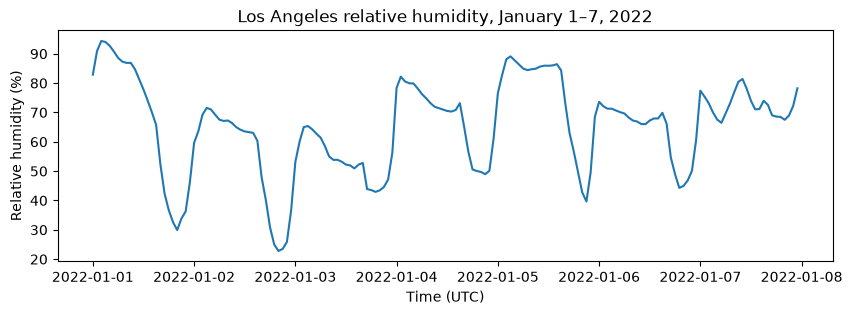

In [8]:
time = pd.to_datetime(df[["YEAR", "MO", "DY", "HR"]].rename(columns={"YEAR": "year", "MO": "month", "DY": "day", "HR": "hour"}))
plt.figure(figsize=(10, 3))
plt.plot(time.iloc[:168], df["RH2M"].iloc[:168])
plt.xlabel("Time (UTC)")
plt.ylabel("Relative humidity (%)")
plt.title("Los Angeles relative humidity, January 1–7, 2022")
plt.show()